<a href="https://colab.research.google.com/github/antfolk/BMEN35_2026/blob/main/Session2/BMEN35_Ex2_03_Assignment_Linear_and_Logistic_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment 2: linear and logistic regression

In this assignment you will fit and evaluate two different models using biomedical datasets. In Part A, the outcome is continuous, so you will use linear regression. In Part B, the outcome is a class label, so you will use logistic regression.

Write code in the marked cells, run the notebook from top to bottom, and answer the questions using your results. Fill in your name above before submitting.

## Fill in your name below

Double-click this text cell and replace the placeholder with your full name before submitting.

**Name:** YOUR NAME HERE

## Metrics documentation

Scikit-learn provides many metrics, and the right metric depends on the type of outcome and the question being asked. Use the official documentation to find the appropriate functions and check their inputs, outputs, and options. In this assignment, use the documentation rather than calculating the metrics by hand.

- [Model evaluation overview](https://scikit-learn.org/stable/modules/model_evaluation.html)
- [Mean absolute error](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.mean_absolute_error.html)
- [Mean squared error](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.mean_squared_error.html)
- [R² score](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.r2_score.html)
- [Confusion matrix](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html)
- [Accuracy](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.accuracy_score.html)
- [Precision](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.precision_score.html)
- [Recall](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.recall_score.html)
- [F1 score](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.f1_score.html)
- [ROC-AUC score](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_auc_score.html)

For each part, use metrics that match the outcome: regression metrics for a continuous target and classification metrics for class labels. State which positive class you use for the classification metrics.

## Part A — Linear regression: predict disease progression

The diabetes dataset contains ten baseline measurements for each observation. Its target is a quantitative measure of disease progression one year after baseline. This is a continuous outcome, not a diagnosis or a prediction of whether someone has diabetes.

We will inspect the data, create a train/test split, compare a simple mean-prediction baseline with linear regression, and evaluate the predictions using regression metrics.

### 1. Load and inspect the dataset

In [14]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes, load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn import metrics

# Load the diabetes dataset.
diabetes = load_diabetes()
X_reg = diabetes.data
y_reg = diabetes.target
regression_feature_names = diabetes.feature_names

print('Number of observations:', X_reg.shape[0])
print('Number of features:', X_reg.shape[1])
print('Feature names:', regression_feature_names)
print('First five rows, first three features:')
print(np.round(X_reg[:5, :3], 3))
print('First five target values:')
print(y_reg[:5])

Number of observations: 442
Number of features: 10
Feature names: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']
First five rows, first three features:
[[ 0.038  0.051  0.062]
 [-0.002 -0.045 -0.051]
 [ 0.085  0.051  0.044]
 [-0.089 -0.045 -0.012]
 [ 0.005 -0.045 -0.036]]
First five target values:
[151.  75. 141. 206. 135.]


The target is numeric and continuous. Look at its distribution and at one feature against the target. For this plot, feature index 2 is BMI. The plot helps us see what the measurements look like; it does not show the relationship with all ten features at once.

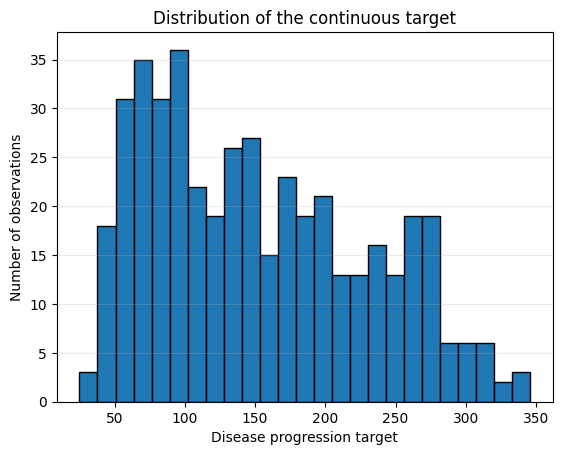

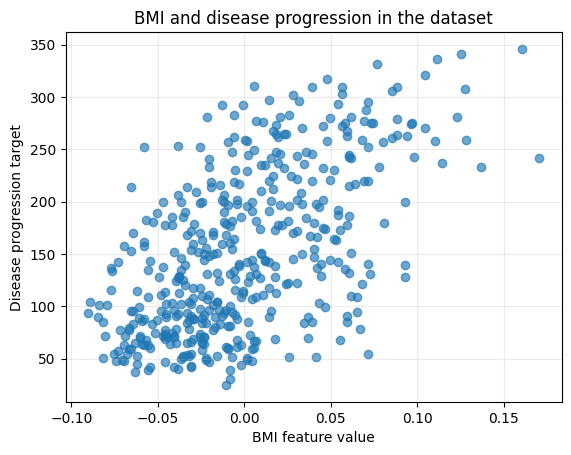

In [15]:
plt.hist(y_reg, bins=25, edgecolor='black')
plt.xlabel('Disease progression target')
plt.ylabel('Number of observations')
plt.title('Distribution of the continuous target')
plt.grid(axis='y', alpha=0.25)
plt.show()

# Plot BMI (feature index 2) against the continuous target.
bmi_column = regression_feature_names.index('bmi')
plt.scatter(X_reg[:, bmi_column], y_reg, alpha=0.65)
plt.xlabel('BMI feature value')
plt.ylabel('Disease progression target')
plt.title('BMI and disease progression in the dataset')
plt.grid(alpha=0.25)
plt.show()

### 2. Split the observations

Keep a test set aside for the final comparison. The model and baseline must be fitted using training observations only. The diabetes dataset has already been prepared with numerical features, so we will use the original feature values here.

In [16]:
X_reg_train, X_reg_test, y_reg_train, y_reg_test = train_test_split(
    X_reg, y_reg, test_size=0.25, random_state=42
)

print('Training observations:', len(y_reg_train))
print('Test observations:', len(y_reg_test))

Training observations: 331
Test observations: 111


### 3. Fit a baseline and a linear regression model

A mean baseline predicts the average training target for every test observation. It gives us a simple reference: a linear model should be evaluated against this baseline, not in isolation.

**Your task:** complete the code to fit the baseline and the linear regression model. Use the three familiar steps: create the estimator, fit it on the training data, and predict the test targets.

In [19]:
baseline_reg = DummyRegressor(strategy = 'mean')
baseline_reg.fit(X_reg_train, y_reg_train)
baseline_reg_prediction = baseline_reg.predict(X_reg_test)

linear_model = LinearRegression()
linear_model.fit(X_reg_train, y_reg_train)
linear_prediction = linear_model.predict(X_reg_test)

print('First five true test targets:', y_reg_test[:5])
print('First five linear predictions:', np.round(linear_prediction[:5], 1))

First five true test targets: [219.  70. 202. 230. 111.]
First five linear predictions: [137.9 182.5 129.9 292.6 124.9]


### 4. Choose regression metrics from the documentation

Read the linked metric documentation and select functions for these questions:

- How far are predictions from the true values on average, in the original target units?
- How much do large errors affect the summary?
- How much variation in the target is explained relative to a mean-prediction reference?

Use the correct scikit-learn metrics for the baseline and the linear model. RMSE is the square root of MSE, so you can calculate it with NumPy after looking up mean squared error. Write each metric call in the code cell.

In [20]:
# TODO: use the regression metric documentation to complete these calls.
baseline_mae = metrics.mean_absolute_error(y_reg_test, baseline_reg_prediction)
baseline_mse = metrics.mean_squared_error(y_reg_test, baseline_reg_prediction)
baseline_rmse = np.sqrt(baseline_mse)
baseline_r2 = metrics.r2_score(y_reg_test, baseline_reg_prediction)

linear_mae = metrics.mean_absolute_error(y_reg_test, linear_prediction)
linear_mse = metrics.mean_squared_error(y_reg_test, linear_prediction)
linear_rmse = np.sqrt(linear_mse)
linear_r2 = metrics.r2_score(y_reg_test, linear_prediction)

print('Baseline  | MAE:', round(baseline_mae, 2),
      '| RMSE:', round(baseline_rmse, 2), '| R2:', round(baseline_r2, 3))
print('Linear reg| MAE:', round(linear_mae, 2),
      '| RMSE:', round(linear_rmse, 2), '| R2:', round(linear_r2, 3))

Baseline  | MAE: 65.53 | RMSE: 74.88 | R2: -0.014
Linear reg| MAE: 41.55 | RMSE: 53.37 | R2: 0.485


Plot the predicted values against the true test targets. If predictions were perfect, all points would lie on the diagonal line. Use the same axes so that the comparison is easy to see.

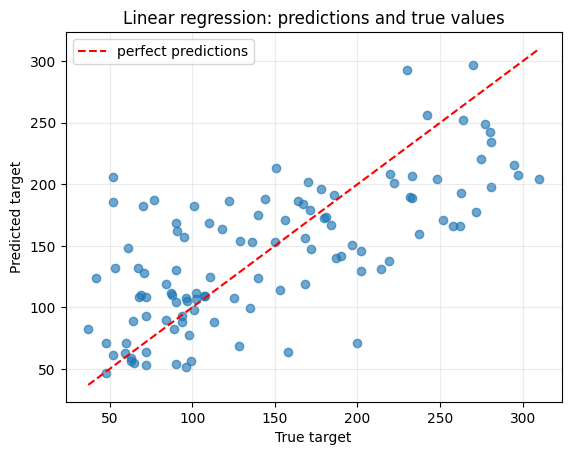

In [21]:
plt.scatter(y_reg_test, linear_prediction, alpha=0.65)
low = min(y_reg_test.min(), linear_prediction.min())
high = max(y_reg_test.max(), linear_prediction.max())
plt.plot([low, high], [low, high], 'r--', label='perfect predictions')
plt.xlabel('True target')
plt.ylabel('Predicted target')
plt.title('Linear regression: predictions and true values')
plt.legend()
plt.grid(alpha=0.25)
plt.show()

### Questions about linear regression

1. Does linear regression improve on the mean baseline for MAE and RMSE in your run?


2. Which metric is in the original target units? What do MAE and RMSE tell you differently?

We can see from the comparison between the baseline and linear regression models that linear regression performs better than the mean baseline because it has lower MAE and RMSE values, meaning that its predictions are more accurate.

3. What does the R² value say about predictions compared with a mean-based reference?

A mean based reference assigns the average target value as the prediction for all observations. R^2 tells us whether our predictions re better or worse than simply using this average.


4. Describe one pattern or limitation you notice in the predicted-versus-true plot.

The model tends to predict highr values when the true target values are low and lower values when the true target values are high. This indicates that the model struggles to predict extreme values accurately.

5. Why should the target not be interpreted as a diagnosis?
The target should not ne interpreted as a diagnosis because it represent a numerical measure of disease progression, rather than indicating wheter a patient has diabetes. Therefore, it describes disease progression adn not a medical diagnosis.

## Part B — Logistic regression: classify benign and malignant samples

We now use the breast-cancer dataset. Each observation has measurements of cell nuclei from a digitized image of a breast mass. The target has two classes. We will define **malignant as the positive class (1)** and benign as the negative class (0).

This is a teaching exercise, not a diagnostic tool. The point is to practice classification and metric selection, not to make clinical decisions.

### 5. Load and inspect the classification dataset

In [ ]:
cancer = load_breast_cancer()
X_cls = cancer.data

# The original target uses 0=malignant and 1=benign.
# Recode it so that 1 means the positive class: malignant.
y_cls = (cancer.target == 0).astype(int)

print('Number of observations:', X_cls.shape[0])
print('Number of features:', X_cls.shape[1])
print('Feature names, first five:', cancer.feature_names[:5])
print('First five rows, first five features:')
print(np.round(X_cls[:5, :5], 2))
print('First five recoded labels:', y_cls[:5])

Check the class balance before fitting a classifier. Then visualize two features. The plot shows only two of the thirty available features.

In [ ]:
number_benign = np.sum(y_cls == 0)
number_malignant = np.sum(y_cls == 1)
print('Benign (0):', number_benign)
print('Malignant (1):', number_malignant)

plt.bar(['benign (0)', 'malignant (1)'],
        [number_benign, number_malignant],
        color=['steelblue', 'firebrick'], edgecolor='black')
plt.ylabel('Number of observations')
plt.title('Class balance')
plt.grid(axis='y', alpha=0.25)
plt.show()

radius_column = list(cancer.feature_names).index('mean radius')
texture_column = list(cancer.feature_names).index('mean texture')
for class_value, label, color in [(0, 'benign', 'steelblue'), (1, 'malignant', 'firebrick')]:
    class_rows = y_cls == class_value
    plt.scatter(X_cls[class_rows, radius_column],
                X_cls[class_rows, texture_column],
                label=label, color=color, alpha=0.65)
plt.xlabel('Mean radius')
plt.ylabel('Mean texture')
plt.title('Two features; colour shows the true class')
plt.legend()
plt.grid(alpha=0.25)
plt.show()

### 6. Split the data and make a baseline

Use stratification to keep the malignant proportion similar in the training and test sets. Fit a majority-class baseline using training labels only. This baseline ignores every feature. Compare it with logistic regression later, especially on its ability to identify malignant observations.

In [ ]:
X_cls_train, X_cls_test, y_cls_train, y_cls_test = train_test_split(
    X_cls, y_cls, test_size=0.25, random_state=42, stratify=y_cls
)

print('Training rows:', len(y_cls_train))
print('Test rows:', len(y_cls_test))
print('Malignant fraction in training:', round(np.mean(y_cls_train), 3))
print('Malignant fraction in test:', round(np.mean(y_cls_test), 3))

baseline_cls = DummyClassifier(strategy='most_frequent')
baseline_cls.fit(X_cls_train, y_cls_train)
baseline_prediction = baseline_cls.predict(X_cls_test)
print('Baseline predictions, first ten:', baseline_prediction[:10])

### 7. Fit logistic regression

Feature values have different scales, so we put a standard scaler before logistic regression. The pipeline fits the scaler using training data only and then fits the classifier.

**Your task:** create the pipeline, fit it on training observations and labels, and calculate both predicted labels and probabilities for the test observations. The probability column for class 1 is the probability of malignant.

In [ ]:
logistic_model = ____
logistic_model.fit(____, ____)

malignant_probability = logistic_model.predict_proba(____)[:, ____]
prediction_at_05 = logistic_model.predict(____)

print('First ten malignant probabilities:',
      np.round(malignant_probability[:10], 3))
print('First ten predicted labels:', prediction_at_05[:10])
print('First ten true labels:', y_cls_test[:10])

### 8. Use scikit-learn's classification metrics

The [model evaluation documentation](https://scikit-learn.org/stable/modules/model_evaluation.html) describes many classification metrics. Read the linked API pages and use the appropriate functions below.

For the confusion matrix, set the label order to [0, 1]. This gives rows for true benign and malignant classes, and columns for predicted benign and malignant classes. The four values are arranged as TN, FP, FN, TP.

For precision and recall, specify the positive class as 1. For ROC-AUC, use the predicted probabilities, not the hard class labels. Look at each function's documentation to check these details.

In [ ]:
# Use the metric API documentation to fill in the correct functions and inputs.
# First evaluate the majority-class baseline.
baseline_accuracy = metrics.____(____, ____)
baseline_recall = metrics.____(____, ____, pos_label=1, zero_division=0)
print('Baseline accuracy:', round(baseline_accuracy, 3))
print('Baseline recall / sensitivity:', round(baseline_recall, 3))

confusion = metrics.____(____, ____, labels=[0, 1])
print('Confusion matrix, rows=true and columns=predicted [0, 1]:')
print(confusion)

accuracy = metrics.____(____, ____)
precision = metrics.____(____, ____, pos_label=1, zero_division=0)
recall = metrics.____(____, ____, pos_label=1, zero_division=0)
f1 = metrics.____(____, ____, pos_label=1, zero_division=0)
roc_auc = metrics.____(____, ____)

print('Logistic regression accuracy:', round(accuracy, 3))
print('Precision for malignant:', round(precision, 3))
print('Recall / sensitivity for malignant:', round(recall, 3))
print('F1 for malignant:', round(f1, 3))
print('ROC-AUC:', round(roc_auc, 3))

### 9. Compare two probability thresholds

Predicted probabilities do not change when we change the threshold; only the class labels change. A lower threshold usually labels more observations malignant. This may identify more malignant samples, but may also create more false positives.

Use the documentation to calculate recall for thresholds 0.25 and 0.75. Compare the confusion matrices and describe the trade-off. Do not assume one threshold is always best; explain which errors matter for the question you are considering.

In [ ]:
for threshold in [0.25, 0.50, 0.75]:
    prediction = (malignant_probability >= threshold).astype(int)

    # TODO: use the confusion_matrix function from sklearn.metrics.
    threshold_confusion = metrics.____(____, ____, labels=[0, 1])

    # TODO: use the recall function with malignant (label 1) as positive.
    threshold_recall = metrics.____(____, ____, pos_label=1, zero_division=0)

    print('Threshold:', threshold)
    print('Confusion matrix [TN FP; FN TP]:')
    print(threshold_confusion)
    print('Sensitivity / recall:', round(threshold_recall, 3))

### Questions about logistic regression

1. What does a false negative mean in this dataset? What does a false positive mean?
2. Compare accuracy with recall for the majority-class baseline and logistic regression. Why can these tell different stories?
3. Which metric would you focus on if the main question were “How many malignant cases did the model identify?” What does that metric leave out?
4. How did the confusion matrix change as the threshold changed?
5. Why does ROC-AUC use probabilities rather than predicted labels?
6. Why can these results not be used to make a diagnosis or a clinical recommendation?

## Submission checklist

- [ ] My name is at the top of the notebook.
- [ ] I inspected both datasets and included the requested plots.
- [ ] I fitted a mean baseline and a linear regression model.
- [ ] I chose regression metrics using the scikit-learn documentation and compared baseline and model.
- [ ] I fitted a majority-class baseline and a logistic-regression pipeline.
- [ ] I used scikit-learn's classification metrics with malignant (1) as the positive class.
- [ ] I compared the requested probability thresholds and answered the questions using my results.
- [ ] I ran the notebook from top to bottom.

## Download and submit your notebook

When you have finished the assignment:

1. Run the notebook cells from top to bottom and keep the outputs with your work.
2. In Google Colab, choose **File → Download → Download .ipynb**. This downloads a Jupyter notebook file with the ipynb extension.
3. Submit the downloaded ipynb file in Canvas.

Submit the ipynb notebook file. Do not submit a PDF, screenshots, or a Python script.